In [1]:
from db_queries import get_ids, get_population, get_covariate_estimates, get_best_model_versions, get_outputs
from get_draws.api import get_draws
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

# Back-of-the-envelope: CVD and ambient PM pollution
How many additional CVD deaths (or some other outcome measure?) will there be with an increase in air pollution levels in Washington State?

- A = CVD deaths (or another outcome metric?)  
- B = Effect of air pollution on CVD outcomes (separate RRs for IHD and stroke? Other forms of CVD?) 
- C = Change in air pollution levels (what units? From FHS estimate?)



``A * B * C = X``, where X is the additional deaths with each C increase in air pollution levels 

Related links: 
- [Ambient PM pollution Methods Appendix 2021](https://www.healthdata.org/gbd/methods-appendices-2021/ambient-particulate-matter-pollution)
- [Syl's B-O-E calculation notebook from CVD sim](https://github.com/ihmeuw/vivarium_research_nih_us_cvd/blob/main/data_testing_exploration/Back_of_envelope.ipynb)
- [SharePoint notes](https://uwnetid.sharepoint.com/sites/ihme_simulation_science_team/_layouts/15/doc.aspx?sourcedoc={89f5b873-f051-4e2f-9032-9d5a42c59bda}&action=edit)
- [Abie's slides on B-O-E calculations](https://www.dropbox.com/scl/fi/04fy98nlj158wlpw44peb/vivarium_back_of_envelop_method.pptx?rlkey=v8n9m0qi2ts2k3k0c836dhp7z&e=1&dl=0)
- [CVD Concept Model docs](https://vivarium-research.readthedocs.io/en/latest/models/concept_models/vivarium_us_cvd/concept_model.html)

# First calculation: How many CVD deaths are currently attributable to ambient air pollution? 
``CVD deaths due to air pollution = total CVD deaths * PAF``

In [2]:
# CVD deaths (count) in Washington State in 2021
cvd_deaths = get_draws(location_id=570, # Washington State
         gbd_id_type='cause_id',
         gbd_id=[491],
         source='codcorrect',
         year_id=2021,
         release_id=9,
         measure_id=1,
         metric_id=1
         ).groupby(['age_group_id','sex_id']).sum().drop(columns=['cause_id','location_id','measure_id','year_id','metric_id','version_id'])
cvd_deaths

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/get_draws/api.py:194: UserWarning: No version_id was specified, so get_draws will automatically determine a best version ID to use from the given parameters. If you want to retrieve a specific version please pass a version_id directly.
  warnings.warn(


draw_0       draw_1      draw_10     draw_100  \
age_group_id sex_id                                                       
2            1          0.297548     0.352214     0.333971     0.305307   
             2          0.240381     0.271667     0.252824     0.233715   
3            1          0.432524     0.380855     0.366530     0.438973   
             2          0.197086     0.225192     0.223151     0.187841   
6            1          0.644124     0.555617     0.601061     0.674758   
             2          0.668968     0.929973     0.806333     0.732444   
7            1          1.308218     0.961569     0.993272     1.110869   
             2          1.043339     0.970133     0.934117     0.952478   
8            1          2.608871     2.409925     3.918251     3.721536   
             2          2.079470     2.489154     2.259126     2.158330   
9            1          6.130197     6.362545     8.507154     8.136050   
             2          4.269463     4.281992     3.942102     3.796234   
10           1         14.432584    12.294439    15.382087    14.513396   
             2          6.765625     7.537112     7.416615     7.737818   
11           1         24.337990    21.098447    30.649446    36.019195   
             2         12.409346    13.271101    11.732512    13.712272   
12           1         43.957679    36.803324    54.083510    57.134252   
             2         20.104984    21.230016    24.018020    22.607118   
13           1         79.398661    58.943293    87.003384   108.237500   
             2         27.994744    36.464702    37.554908    33.556958   
14           1        108.015627    89.661307   142.640725   152.603312   
             2         53.054688    55.295019    60.274071    56.390213   
15           1        249.047654   188.930933   284.927081   298.636948   
             2         96.491895   109.641937   111.682707   109.728951   
16           1        401.091660   325.750091   466.896477   469.758637   
             2        162.006047   175.970154   173.867321   174.081368   
17           1        647.956492   473.591384   709.685054   770.765007   
             2        266.258528   282.030760   276.754674   280.637655   
18           1        845.183929   637.541184   904.863275   935.882891   
             2        386.244681   410.336034   416.208103   406.538359   
19           1        987.338524   775.796736  1143.234137  1137.962588   
             2        645.758662   658.688194   574.566509   616.214490   
20           1       1139.461250   846.971779  1216.763710  1328.609411   
             2        804.909266   872.880937   815.857242   717.544399   
30           1       1202.183708   965.198988  1283.325947  1304.648214   
             2       1113.460213  1160.399928  1040.239563   980.119143   
31           1       1276.737682  1115.937054  1346.411704  1255.218380   
             2       1405.117924  1504.643055  1320.503195  1213.407597   
32           1       1073.730389   924.745502  1057.181395  1032.385181   
             2       1663.326216  1738.636819  1521.590315  1396.242702   
34           1          0.235713     0.350800     0.267445     0.214068   
             2          0.134926     0.170571     0.121523     0.112068   
235          1        580.437066   456.375999   528.717038   521.517542   
             2       1392.679310  1391.767751  1217.979241  1128.728609   
238          1          0.598882     0.819592     0.933854     0.725159   
             2          0.561129     0.676375     0.623455     0.672557   
388          1          1.135335     1.401818     1.491391     1.340132   
             2          0.755515     0.844917     0.894562     0.938564   
389          1          0.325967     0.304561     0.307289     0.355411   
             2          0.202587     0.319424     0.236359     0.260476   

                        draw_101     draw_102     draw_103     draw_104  \
age_group_id sex_id                               

In [ ]:
# Ambient air pollution PAF
air_pm_paf = get_draws(location_id=570, # Washington State
         gbd_id_type='rei_id',
         gbd_id=86, # Ambient particulate matter pollution
         source='paf',
         year_id=2021,
         release_id=9,
         measure_id=11 # Relative risk
         )

air_pm_paf
# Does this call return PAFs or RRs? From source='paf' but using measure ID for relative risk.
# If this is an RR, I need to calculate the PAF using RRmax and the age- and sex-specific SEV (see below).

,rei_id,modelable_entity_id,location_id,year_id,age_group_id,sex_id,cause_id,measure_id,metric_id,draw_0,...,draw_991,draw_992,draw_993,draw_994,draw_995,draw_996,draw_997,draw_998,draw_999,model_version_id
0,86,8746,570,2021,34,1,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012618,0.021714,0.023231,0.001872,728145
1,86,8746,570,2021,34,2,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012629,0.021714,0.023231,0.001872,728145
2,86,8746,570,2021,238,1,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012618,0.021714,0.023231,0.001872,728145
3,86,8746,570,2021,238,2,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012629,0.021714,0.023231,0.001872,728145
4,86,8746,570,2021,388,1,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012618,0.021714,0.023231,0.001872,728145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,86,8746,570,2021,3,2,383,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728145
608,86,8746,570,2021,3,2,384,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728145
609,86,8746,570,2021,3,2,385,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728145
610,86,8746,570,2021,3,2,686,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728145


In [21]:
get_draws(location_id=570, # Washington State
         gbd_id_type='rei_id',
         gbd_id=380, # Particulate matter pollution
         source='paf',
         year_id=2021,
         release_id=9,
         measure_id=11 # Relative risk
         )

# Is there a difference between Particulate matter pollution (rei_id=380) and Ambient particulate matter pollution (rei_id=86)?

,rei_id,modelable_entity_id,location_id,year_id,age_group_id,sex_id,cause_id,measure_id,metric_id,draw_0,...,draw_991,draw_992,draw_993,draw_994,draw_995,draw_996,draw_997,draw_998,draw_999,model_version_id
0,380,20260,570,2021,34,1,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012623,0.021714,0.023231,0.001872,728144
1,380,20260,570,2021,34,2,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012636,0.021714,0.023231,0.001872,728144
2,380,20260,570,2021,238,1,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012623,0.021714,0.023231,0.001872,728144
3,380,20260,570,2021,238,2,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012636,0.021714,0.023231,0.001872,728144
4,380,20260,570,2021,388,1,322,3,2,0.008767,...,0.020052,0.012548,0.050783,-0.005757,0.017936,0.012623,0.021714,0.023231,0.001872,728144
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
639,380,20260,570,2021,3,2,383,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728144
640,380,20260,570,2021,3,2,384,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728144
641,380,20260,570,2021,3,2,385,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728144
642,380,20260,570,2021,3,2,686,4,2,0.000000,...,0.007346,0.000000,0.000000,0.045308,0.000000,0.000000,0.000000,0.000000,0.000000,728144


In [4]:
air_pm_paf.measure_id.value_counts()
# measure_id = 4 for YLLs (fatal)

3    306
4    306
Name: measure_id, dtype: int64

In [5]:
air_pm_paf = air_pm_paf.loc[air_pm_paf.measure_id == 4]

In [6]:
air_pm_paf.metric_id.value_counts()
# metric_id = 2 means percentage -- should divide by 100 to get a proportion instead? 

2    306
Name: metric_id, dtype: int64

In [22]:
# Filter to CVD cause
air_pm_paf.loc[air_pm_paf.cause_id==491]

# Should I filter to a specific sub-cause instead?

,rei_id,modelable_entity_id,location_id,year_id,age_group_id,sex_id,cause_id,measure_id,metric_id,draw_0,...,draw_991,draw_992,draw_993,draw_994,draw_995,draw_996,draw_997,draw_998,draw_999,model_version_id


In [8]:
air_pm_paf.cause_id.value_counts() 

# Evidently there is no ambient air pollution PAF for CVD as an umbrella cause, but we have sub-causes:
#  cause_id=493 is Ischemic Heart Disease
#  cause_id=495 is Ischemic Stroke
#  cause_id=496 is Intracerebral Hemorrhage
#  cause_id=497 is Subarachnoid Hemorrhage

322     50
426     30
493     30
495     30
496     30
497     30
509     30
976     30
302      4
328      4
329      4
332      4
337      4
381      4
382      4
383      4
384      4
385      4
1061     4
686      2
Name: cause_id, dtype: int64

In [9]:
# Filter to CVD sub-causes and sum to get overall CVD PAF 
cvd_paf = air_pm_paf.loc[air_pm_paf.cause_id.isin([493,495,496,497])]
cvd_paf

,rei_id,modelable_entity_id,location_id,year_id,age_group_id,sex_id,cause_id,measure_id,metric_id,draw_0,...,draw_991,draw_992,draw_993,draw_994,draw_995,draw_996,draw_997,draw_998,draw_999,model_version_id
382,86,8746,570,2021,10,1,493,4,2,0.007215,...,0.009083,0.031505,0.036700,0.007934,0.013483,0.015874,0.016380,0.025890,0.004545,728145
383,86,8746,570,2021,10,2,493,4,2,0.007215,...,0.009083,0.031505,0.036701,0.007934,0.013483,0.015888,0.016380,0.025890,0.004545,728145
384,86,8746,570,2021,11,1,493,4,2,0.007215,...,0.009083,0.031505,0.036700,0.007934,0.013483,0.015874,0.016380,0.025890,0.004545,728145
385,86,8746,570,2021,11,2,493,4,2,0.007215,...,0.009083,0.031505,0.036701,0.007934,0.013483,0.015888,0.016380,0.025890,0.004545,728145
386,86,8746,570,2021,12,1,493,4,2,0.007215,...,0.009083,0.031505,0.036700,0.007934,0.013483,0.015874,0.016380,0.025890,0.004545,728145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,86,8746,570,2021,31,2,497,4,2,0.004375,...,0.007625,0.018054,0.030200,0.005667,0.009688,0.012310,0.013636,0.027282,0.003455,728145
498,86,8746,570,2021,32,1,497,4,2,0.004375,...,0.007625,0.018054,0.030200,0.005667,0.009688,0.012299,0.013636,0.027282,0.003455,728145
499,86,8746,570,2021,32,2,497,4,2,0.004375,...,0.007625,0.018054,0.030200,0.005667,0.009688,0.012310,0.013636,0.027282,0.003455,728145
500,86,8746,570,2021,235,1,497,4,2,0.004375,...,0.007625,0.018054,0.030200,0.005667,0.009688,0.012299,0.013636,0.027282,0.003455,728145


In [10]:
cvd_paf = cvd_paf.groupby(['age_group_id','sex_id']).sum().drop(columns=['rei_id','modelable_entity_id', # Group by 'cause_id' too to not sum across sub-causes as I currently do here
                                                                   'year_id','measure_id',
                                                                   'metric_id','model_version_id',
                                                                   'location_id'])
cvd_paf

# Looks like the PAF (or if this is an RR, the RR) is the same across all ages and sexes

cause_id    draw_0    draw_1    draw_2    draw_3  \
age_group_id sex_id                                                     
10           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
11           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
12           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
13           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
14           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
15           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
16           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
17           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
18           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
19           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
20           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
30           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
31           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
32           1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   
235          1           1981  0.020339  0.140733  0.036362  0.073452   
             2           1981  0.020339  0.140733  0.036362  0.073452   

                       draw_4   draw_5    draw_6    draw_7    draw_8  ...  \
age_group_id sex_id                                                   ...   
10           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
11           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
12           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
13           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
14           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
15           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
16           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
17           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
18           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.050588  ...   
19           1       0.142791  0.02297  0.043158  0.051011  0.050588  ...   
             2       0.142791  0.02297  0.043158  0.051072  0.05058

In [12]:
cvd_deaths_due_to_air_pm = cvd_deaths * cvd_paf
cvd_deaths_due_to_air_pm

cause_id     draw_0      draw_1     draw_10   draw_100  \
age_group_id sex_id                                                           
2            1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
3            1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
6            1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
7            1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
8            1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
9            1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
10           1            NaN   0.293544    1.730228    1.190471   0.196808   
             2            NaN   0.137606    1.060717    0.574026   0.104948   
11           1            NaN   0.495011    2.969239    2.372062   0.488436   
             2            NaN   0.252394    1.867676    0.908064   0.185980   
12           1            NaN   0.894056    5.179427    4.185702   0.774765   
             2            NaN   0.408915    2.987755    1.858929   0.306621   
13           1            NaN   1.614890    8.295242    6.733480   1.467746   
             2            NaN   0.569385    5.131772    2.906647   0.455134   
14           1            NaN   2.196931   12.618267   11.039439   2.069365   
             2            NaN   1.079080    7.781811    4.665048   0.764822   
15           1            NaN   5.065382   26.588738   22.051451   4.049643   
             2            NaN   1.962549   15.430193    8.643935   1.488257   
16           1            NaN   8.157807   45.843651   36.134666   6.370126   
             2            NaN   3.295042   24.764734   13.456854   2.361072   
17           1            NaN  13.178793   66.649738   54.924879  10.451899   
             2            NaN   5.415434   39.690916   21.420053   3.806298   
18           1            NaN  17.190203   89.722817   70.030368  12.690967   
             2            NaN   7.855834   57.747648   32.213366   5.513894   
19           1            NaN  20.081487  109.179878   88.478680  15.431254   
             2            NaN  13.134091   92.698889   44.469872   8.357738   
20           1            NaN  23.175512  119.196526   94.169377  18.016505   
             2            NaN  16.371056  122.842786   63.145114   9.732079   
30           1            NaN  24.451225  135.834946   99.320849  17.691581   
             2            NaN  22.646677  163.306075   80.511690  13.293389   
31           1            NaN  25.967578  157.048703  104.203265  17.021292   
             2            NaN  28.578705  211.752298  102.203327  16.457488   
32           1            NaN  21.838611  130.141822   81.818773  13.999579   
             2            NaN  33.830406  244.682844  117.766919  18.937287   
34           1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
235          1            NaN  11.805514   64.226973   40.919164   7.071998   
             2            NaN  28.325716  195.867065   94.268254  15.308984   
238          1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
388          1            NaN        NaN         NaN         NaN        NaN   
             2            NaN        NaN         NaN         NaN        NaN   
389          1            NaN        NaN         NaN         NaN       

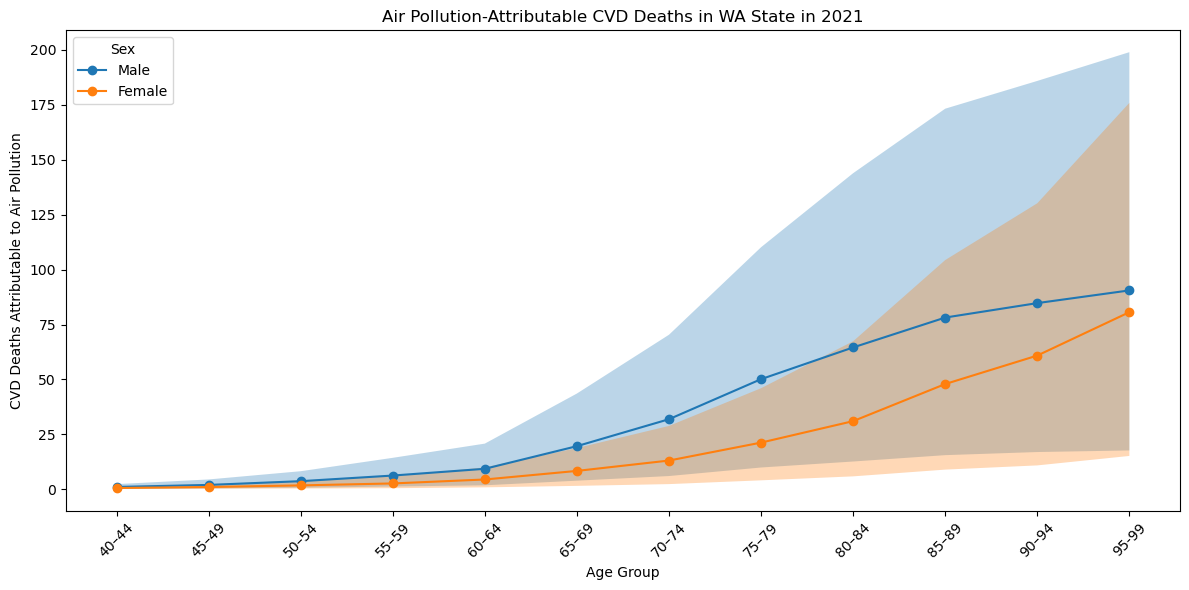

In [ ]:

age_group_map = {
    2: "0–4", 3: "5–9", 4: "10–14", 5: "15–19", 6: "20–24",
    7: "25–29", 8: "30–34", 9: "35–39", 10: "40–44",
    11: "45–49", 12: "50–54", 13: "55–59", 14: "60–64",
    15: "65–69", 16: "70–74", 17: "75–79", 18: "80–84",
    19: "85–89", 20: "90–94", 30: "95-99"
}
sex_map = {
    1: "Male",
    2: "Female"
}

s = cvd_deaths_due_to_air_pm.copy()
s["mean"] = s.loc[:, "draw_0":"draw_999"].mean(axis=1)
s["lower"] = s.loc[:, "draw_0":"draw_999"].quantile(0.025, axis=1)
s["upper"] = s.loc[:, "draw_0":"draw_999"].quantile(0.975, axis=1)
s = s.reset_index()
s["age_group_name"] = s["age_group_id"].map(age_group_map)
s = s.dropna(subset=["age_group_name"])

ordered_ages = [age_group_map[i] for i in sorted(age_group_map) if i in s["age_group_id"].unique()]
s["age_group_name"] = pd.Categorical(
    s["age_group_name"], categories=ordered_ages, ordered=True
)
s = s.sort_values("age_group_name")


fig, ax = plt.subplots(figsize=(12, 6))
for sex in sorted(s["sex_id"].unique()):
    subset = s[s["sex_id"] == sex]
    x = subset["age_group_name"]
    y = subset["mean"]
    lower = subset["lower"]
    upper = subset["upper"]

    label = sex_map.get(sex, f"Sex {sex}")
    ax.plot(x, y, label=label, marker='o')
    ax.fill_between(x, lower, upper, alpha=0.3)
ax.set_xlabel("Age Group")
ax.set_ylabel("CVD Deaths Attributable to Air Pollution")
ax.set_title("Air Pollution-Attributable CVD Deaths in WA State in 2021")
ax.legend(title="Sex")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## Check: Calculate the PAF using ambient PM pollution SEVs from GBD, and compare to PAFs (?) pulled directly from get_covariate_estimates above
``PAF = (SEV(RRmax - 1)) / (1 + SEV(RRmax -1))``

In [ ]:
# We can also pull age- and sex-specific SEV for ambient PM pollution from GBD
air_pm_sev = get_covariate_estimates(location_id=570, # Washington State 
         #year_id=2031, # No forecasted values in this covariate - returns data for 1980-2022
         covariate_id=2042,
         release_id=9
         )

air_pm_sev

,model_version_id,covariate_id,covariate_name_short,location_id,location_name,year_id,age_group_id,age_group_name,sex_id,sex,mean_value,lower_value,upper_value
0,38360,2042,SEV_air_pm,570,Washington,1980,2,Early Neonatal,1,Male,0.088047,0.088047,0.088047
1,38360,2042,SEV_air_pm,570,Washington,1980,3,Late Neonatal,1,Male,0.072939,0.072939,0.072939
2,38360,2042,SEV_air_pm,570,Washington,1980,6,5 to 9,1,Male,0.034804,0.034804,0.034804
3,38360,2042,SEV_air_pm,570,Washington,1980,7,10 to 14,1,Male,0.034804,0.034804,0.034804
4,38360,2042,SEV_air_pm,570,Washington,1980,8,15 to 19,1,Male,0.034804,0.034804,0.034804
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2145,38360,2042,SEV_air_pm,570,Washington,2022,34,2 to 4,2,Female,0.020175,0.020175,0.020175
2146,38360,2042,SEV_air_pm,570,Washington,2022,235,95 plus,2,Female,0.043529,0.043529,0.043529
2147,38360,2042,SEV_air_pm,570,Washington,2022,238,12 to 23 months,2,Female,0.020175,0.020175,0.020175
2148,38360,2042,SEV_air_pm,570,Washington,2022,388,1-5 months,2,Female,0.020175,0.020175,0.020175


In [5]:
# And the age-standardized SEV for ambient PM pollution from GBD
get_covariate_estimates(location_id=570, # Washington State 
         #year_id=2031,  # No forecasted values in this covariate - returns data for 1980-2022
         covariate_id=2043,
         release_id=9
         )

,model_version_id,covariate_id,covariate_name_short,location_id,location_name,year_id,age_group_id,age_group_name,sex_id,sex,mean_value,lower_value,upper_value
0,38296,2043,SEV_agestd_air_pm,570,Washington,1980,27,Age-standardized,3,Both,0.051995,0.051995,0.051995
1,38296,2043,SEV_agestd_air_pm,570,Washington,1981,27,Age-standardized,3,Both,0.052496,0.052496,0.052496
2,38296,2043,SEV_agestd_air_pm,570,Washington,1982,27,Age-standardized,3,Both,0.053081,0.053081,0.053081
3,38296,2043,SEV_agestd_air_pm,570,Washington,1983,27,Age-standardized,3,Both,0.053682,0.053682,0.053682
4,38296,2043,SEV_agestd_air_pm,570,Washington,1984,27,Age-standardized,3,Both,0.054100,0.054100,0.054100
5,38296,2043,SEV_agestd_air_pm,570,Washington,1985,27,Age-standardized,3,Both,0.054396,0.054396,0.054396
6,38296,2043,SEV_agestd_air_pm,570,Washington,1986,27,Age-standardized,3,Both,0.054678,0.054678,0.054678
7,38296,2043,SEV_agestd_air_pm,570,Washington,1987,27,Age-standardized,3,Both,0.054746,0.054746,0.054746
8,38296,2043,SEV_agestd_air_pm,570,Washington,1988,27,Age-standardized,3,Both,0.054509,0.054509,0.054509
9,38296,2043,SEV_agestd_air_pm,570,Washington,1989,27,Age-standardized,3,Both,0.054249,0.054249,0.054249


## Pull forecasted data for 2050
Docs for how to pull FHS results using ``get_outputs()``: https://scicomp-docs.ihme.washington.edu/db_queries/current/get_outputs/forecasted.html

https://hub.ihme.washington.edu/pages/viewpage.action?pageId=349078118&spaceKey=FHSENG&title=FHS%2BResults%2Bvia%2BGet_Outputs

FHS Foresight Viz Results Tool: https://vizhub.healthdata.org/gbd-foresight/

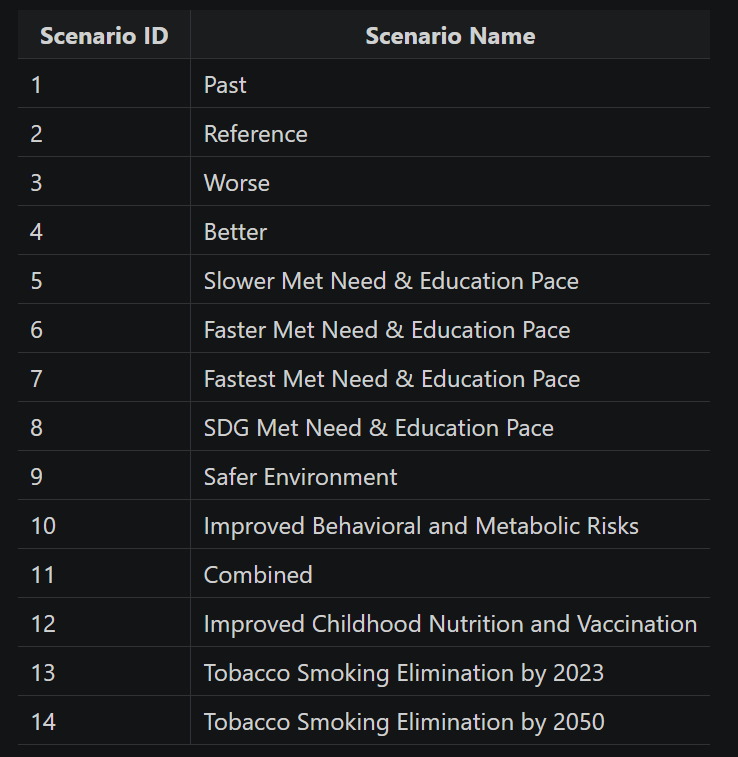

In [27]:
sev_reference = get_outputs(
    "rei",
    rei_id=86,
    location_id=570,
    release_id=6,
    measure_id=29,
    metric_id=3,
    year_id=2030,
    forecasted=True,
    scenario_id=2,
)
sev_reference

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/db_queries/legacy/get_outputs_helpers/formatting.py:263: UserWarning: When looking for rei_names, we are missing values given rei_set_id: 21. Filling with latest names from rei db table. WARNING: Be very careful if sharing these results with collaborators!!
  warnings.warn(


,age_group_id,location_id,measure_id,metric_id,rei_id,scenario_id,sex_id,year_id,age_group_name,expected,...,location_type,measure,measure_name,metric_name,rei,rei_name,sex,val,upper,lower
0,22,570,29,3,86,2,3,2030,All Ages,False,...,admin1,sev,Summary exposure value,Rate,air_pm,Ambient particulate matter pollution,Both,0.03163,0.05742,0.011414


In [38]:
sev_worse = get_outputs(
    "rei",
    rei_id=86,
    location_id=570,
    release_id=6,
    measure_id=29,
    metric_id=3,
    year_id=2030,
    forecasted=True,
    scenario_id=3,
)
sev_worse

# It looks like we can only pull estimates from the FHS reference scenario at the moment?

RuntimeError: no results found. Tables searched were ['output_sev_single_year_v86']. Filters used were {'topic': 'rei', 'scenario_id': [3], 'process_version_id': [65, 77, 71, 62, 74, 86, 80], 'version': 'best', 'compare_version_id': [7], 'release_id': [6], 'conn_def': 'forecasting-prod-db-read', 'year_id': [2030], 'location_set_id': [39], 'location_id': [570], 'age_group_id': [22], 'sex_id': [3], 'cause_set_id': [23], 'cause_id': [294], 'rei_set_id': [21], 'rei_id': [86], 'measure_id': [29], 'metric_id': [3]}

In [ ]:
# We can't pull RRs from FHS estimates, should I use the RRmax from GBD 2021 to calculate the PAF for CVD? 

In [26]:
deaths_reference = get_outputs(
    "cause",
    cause_id=491,
    location_id=570,
    release_id=6,
    measure_id=1,
    metric_id=1,
    year_id=2030,
    forecasted=True,
    scenario_id=2,
)
deaths_reference

,age_group_id,cause_id,location_id,measure_id,metric_id,scenario_id,sex_id,year_id,acause,age_group_name,...,expected,location_name,location_type,measure,measure_name,metric_name,sex,val,upper,lower
0,22,491,570,1,1,2,3,2030,cvd,All Ages,...,False,Washington,admin1,death,Deaths,Number,Both,20844.551841,24270.179207,16779.524844


In [33]:
deaths_worse = get_outputs(
    "cause",
    cause_id=491,
    location_id=570,
    release_id=6,
    measure_id=1,
    metric_id=1,
    year_id=2030,
    forecasted=True,
    scenario_id=3,
)
deaths_worse

RuntimeError: no results found. Tables searched were ['output_cod_single_year_v65']. Filters used were {'topic': 'cause', 'scenario_id': [3], 'process_version_id': [65, 77, 71, 62, 74, 86, 80], 'version': 'best', 'compare_version_id': [7], 'release_id': [6], 'conn_def': 'forecasting-prod-db-read', 'year_id': [2030], 'location_set_id': [39], 'location_id': [570], 'age_group_id': [22], 'sex_id': [3], 'cause_set_id': [23], 'cause_id': [491], 'measure_id': [1], 'metric_id': [1]}